In [19]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm, shapiro

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [18]:
# read the file
df = pd.read_csv("ai_student_impact_dataset.csv")

---
# Part 2 — Descriptive statistics, distribution & probability

# 3. Descriptive statistics of the key variables

In [12]:
# Mean, median and standard deviation of the most important variables
key = ["Pre_Semester_GPA", "Post_Semester_GPA", "GPA_Change",
       "Weekly_GenAI_Hours", "Traditional_Study_Hours", "Skill_Retention_Score"]
df[key].agg(["mean", "median", "std"]).round(3)

,Pre_Semester_GPA,Post_Semester_GPA,GPA_Change,Weekly_GenAI_Hours,Traditional_Study_Hours,Skill_Retention_Score
mean,3.146,3.349,0.203,8.428,11.209,75.798
median,3.210,3.421,0.204,5.800,11.180,76.000
std,0.479,0.496,0.187,8.269,5.156,13.282


**Comment.** On average, GPA went **up** by about +0.20 points over the semester. `Weekly_GenAI_Hours`
has a very large standard deviation compared with its mean: AI use is very different from one
student to another.

# 4. Distribution and probability (Skill Retention Score)
### 4.0 Check normality first (Shapiro-Wilk test)
With 50,000 rows the Shapiro test is run on a random sample of 500 students
(the test is not reliable on very large samples).

In [13]:
sample500 = df["Skill_Retention_Score"].sample(500, random_state=1)
stat, p = shapiro(sample500)
print("Shapiro p-value =", p)
print("Normal?" , "yes" if p > 0.05 else "no (p < 0.05)")

Shapiro p-value = 1.6531891256747777e-05
Normal? no (p < 0.05)


### 4.1 Mean and standard deviation

In [14]:
mu = df["Skill_Retention_Score"].mean()
sigma = df["Skill_Retention_Score"].std()
print("Mean =", round(mu, 2))
print("Standard deviation =", round(sigma, 2))

Mean = 75.8
Standard deviation = 13.28


### 4.2 Histogram with the fitted normal curve

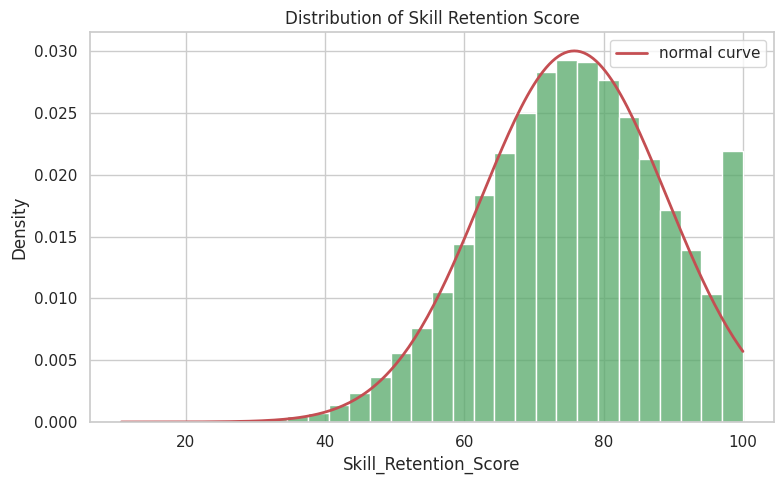

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Skill_Retention_Score"], bins=30, stat="density", color="#55A868")
x = np.linspace(df["Skill_Retention_Score"].min(), df["Skill_Retention_Score"].max(), 200)
plt.plot(x, norm.pdf(x, mu, sigma), "r-", lw=2, label="normal curve")
plt.title("Distribution of Skill Retention Score")
plt.legend(); plt.tight_layout(); plt.show()

### 4.3 P(Skill Retention Score > 85), normal model vs real data

In [16]:
p_normal = norm.sf(85, mu, sigma)             # 1 - cdf
p_real = (df["Skill_Retention_Score"] > 85).mean()
print("Normal model : P(score > 85) =", round(p_normal, 3))
print("Real data    : P(score > 85) =", round(p_real, 3))

Normal model : P(score > 85) = 0.244
Real data    : P(score > 85) = 0.254


### 4.4 The score of the top 10% students (90th percentile)

In [17]:
p90 = norm.ppf(0.90, mu, sigma)
print("90th percentile (normal model) =", round(p90, 2))

90th percentile (normal model) = 92.82


**Comment.**
- Shapiro-Wilk gives p < 0.05, so strictly the score is **not** perfectly normal; but with 50,000
  students even a tiny deviation is detected. The histogram is clearly **bell-shaped**.
- The normal model and the real data agree closely: P(score > 85) ≈ **0.24** with the normal model
  vs **0.25** in the real data. The normal model is therefore a good approximation here.
- The top 10% of students score above ≈ **93/100**.

**Handoff to Ana (Part 3).**